# Шаг 4. Экономика предоплаты и овербукинга

**Проект:** отмены бронирований в отелях — прогноз и политика предоплаты.

**Цель шага:** ответить бизнесу на два вопроса — **с каких броней брать предоплату** (деньги против задетых надёжных гостей) и **насколько овербукировать даты** — и собрать интерактивный отчёт.

**Содержание:** 1. Постановка · 2. Подготовка и сверка с шагом 3 · 3. Пять правил предоплаты · 4. Сравнение при равной доле предоплаты · 5. Разрез по отелям · 6. Чувствительность к допущениям · 7. Овербукинг · 8. Интерактивный отчёт · 9. Схема решения · 10. Выводы · 11. Вся цепочка на одной схеме · 12. Дашборд для бизнеса

In [1]:
from IPython.display import Image
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.dashboard import SCORED_TEST_PATH, scored_frame
from src.data import load_raw
from src.evaluation import DEFAULT_ASSUMPTIONS, best_threshold, loss_curve, losses, score_table, value_at_risk
from src.html_dashboard import build_dashboard
from src.model_features import model_frame
from src.models import fit_calibrator, load_catboost
from src.overbooking import (
    OVERBOOK_CONFIDENCE, OVERBOOKING_PATH, WALK_COSTS, benchmark_proba, benchmark_rates, date_table,
    outcome_table, weekly_table, week_labels,
)
from src.pipeline import build_dataset
from src.plots import FIGURES_DIR, save_figure, set_style
from src.policies import (
    ALL_HOTELS, CURVES_PATH, POLICIES_PATH, best_lead_days, equal_share_curves, policy_sensitivity,
    policy_table, scored,
)
from src.report import RISK_PATH, SECTIONS, build_report, risk_table
from src.split import time_split

%config InlineBackend.figure_format = 'svg'
set_style()
pd.set_option('display.max_colwidth', None)
df, _ = build_dataset(load_raw())
train, valid, test = time_split(df)
(X_valid, y_valid), (X_test, y_test) = model_frame(valid), model_frame(test)

Собираем очищенный датасет шага 1 и делим его по времени так же, как на шаге 3: обучение, валидация, тест (май–август 2017).

Графики выводятся в SVG — чёткие на любом экране.

## 1. Постановка

**Что делаем.** Фиксируем два вопроса бизнеса и все допущения о деньгах в одном месте.

- **Предоплата:** с каких броней её брать, чтобы потерять меньше денег и задеть меньше надёжных гостей (тех, кто и так бы приехал).
- **Овербукинг:** сколько номеров на дату заезда можно продать сверх броней, рассчитывая на отмены.

В данных нет ни цены перепродажи, ни реакции гостей на предоплату, поэтому это допущения — с проверкой чувствительности.

In [2]:
pd.Series({
    'доля стоимости отменённой брони, которую не удаётся перепродать': DEFAULT_ASSUMPTIONS.unsold_share,
    'вероятность потерять надёжного гостя из-за предоплаты': DEFAULT_ASSUMPTIONS.loss_prob,
    'уверенность осторожной оценки отмен на дату': OVERBOOK_CONFIDENCE,
    'цена «гостю не хватило номера», доли стоимости брони': WALK_COSTS[1],
}, name='допущение')

доля стоимости отменённой брони, которую не удаётся перепродать    0.5
вероятность потерять надёжного гостя из-за предоплаты              0.1
уверенность осторожной оценки отмен на дату                        0.9
цена «гостю не хватило номера», доли стоимости брони               1.0
Name: допущение, dtype: float64

Таблица собирает все допущения шага в одном месте:

- **0,5** — половину стоимости отменённой брони отель не успевает перепродать;
- **0,1** — надёжный гость (тот, кто и так бы приехал) уходит к конкуренту из-за требования предоплаты с вероятностью 10 %;
- **0,9** — осторожная оценка числа отмен на дату должна сбываться не реже чем в 90 % случаев;
- **1,0** — если из-за овербукинга гостю не хватило номера, это стоит отелю одну стоимость его брони (переселение, компенсация; в разделе 7 проверяем также 0,5 и 2).

Ни одно из этих чисел не взято из данных: в датасете нет ни цены перепродажи, ни реакции гостей на предоплату, поэтому их влияние на вывод проверяется отдельно.

**Вывод.** Бизнесу нужно решить два вопроса: **с каких броней брать предоплату** и **насколько овербукировать дату** (овербукинг — продажа номеров сверх броней в расчёте на то, что часть гостей отменит).

«Надёжный гость» — тот, кто и так бы приехал: требовать с него предоплату не нужно, а потерять его из-за неё — обидно.

Все денежные допущения заданы в одном месте кода и проверяются: 50 % и 10 % — в разделе 6, уверенность 90 % и цена «гостя без номера» — в разделе 7.

## 2. Подготовка и сверка с шагом 3

**Что делаем.** Берём готовую модель шага 3 — она оценивает для каждой брони вероятность отмены. Модель верно ранжирует брони по риску, но общий уровень отмен запомнила по периоду обучения (24,7 %), а позже отменяли чаще (29,3 % на валидации и 34,8 % на тесте), поэтому её «сырые» проценты занижены. Их поправляет та же «поправочная таблица» (калибровка), что на шаге 3: она переводит прогноз модели в то, как часто такие брони отменяют на самом деле, не меняя порядка броней, и подбирается на валидации (примерно декабрь 2016 — апрель 2017), которую модель не видела. Подробно — ноутбук 03, раздел 7.

Исправленные вероятности применяем к тесту (май–август 2017) — это честная проверка: ни модель, ни таблица этот период не видели. Сначала сверяем цифры с шагом 3 — качество модели и потери при выбранном пороге, — чтобы убедиться, что дальше работаем с той же моделью.

In [3]:
catboost = load_catboost()
raw_valid = catboost.predict_proba(X_valid)[:, 1]
raw_test = catboost.predict_proba(X_test)[:, 1]
calibrator = fit_calibrator(raw_valid, y_valid)
valid_proba, test_proba = calibrator.predict(raw_valid), calibrator.predict(raw_test)
threshold = best_threshold(loss_curve(y_valid, valid_proba, value_at_risk(valid)))
check = score_table(y_test, {'CatBoost (тест)': raw_test}).round(3)
check['порог с валидации'] = threshold
check['потери при пороге, млн €'] = round(losses(y_test, test_proba, value_at_risk(test), threshold)['total']
                                          / 1e6, 2)
check

,pr_auc,roc_auc,порог с валидации,"потери при пороге, млн €"
CatBoost (тест),0.626,0.755,0.17,0.56


PR-AUC (насколько хорошо модель находит отмены среди всех броней) на тесте — 0,626, ROC-AUC (вероятность того, что случайная отменённая бронь получит риск выше, чем случайная неотменённая; 0,5 — угадывание) — 0,755; порог, выбранный по минимуму потерь на валидации, — 0,17; потери на тесте при этом пороге — 0,56 млн €.

Это ровно цифры итога шага 3.

PR-AUC считаем по «сырым» вероятностям CatBoost: поправочная таблица подтягивает прогнозы к реальной доле отмен, не меняя порядка броней, поэтому на ранжирование почти не влияет, а деньги и правила дальше считаем по исправленным вероятностям.

**Вывод.** Сверка с шагом 3 сошлась: PR-AUC теста 0,626, порог 0,17, потери 0,56 млн €. Значит, модель загружена та же, а поправочная таблица, подобранная заново на той же валидации, восстановлена верно.

Все цифры этого шага продолжают шаг 3, а не получены на другой модели.

## 3. Пять правил предоплаты

**Что делаем.** Сравниваем пять правил:

- **как сейчас** (предоплаты нет; брони «без возврата» уже оплачены);
- **со всех**;
- **по сроку брони** (предоплата, если до заезда больше N дней; N подбираем на валидации по минимуму потерь);
- **модель с порогом** шага 3;
- **модель, топ-X %** (предоплата с X % самых рискованных броней; при равном риске порядок фиксирован, поэтому берётся ровно X %).

Для каждого правила считаем потери (та же формула, что на шаге 3), экономию против «как сейчас», долю броней с предоплатой, долю задетых надёжных гостей и долю пойманных отмен. Всё — на тесте.

Брони «без возврата» уже оплачены, и требование предоплаты для них ничего не меняет, поэтому доли задетых надёжных гостей и пойманных отмен считаем только среди броней, которые чего-то стоят отелю при отмене, а долю броней с предоплатой — среди всех броней (так у топ-X % она ровно X %).

In [4]:
valid_s, test_s = scored(valid, valid_proba), scored(test, test_proba)
lead_days = best_lead_days(valid_s)
policies = policy_table(test_s, lead_days, threshold)
policies.to_csv(POLICIES_PATH, index=False)
money = ['missed', 'false_alarm', 'total', 'saving']
overall = policies[policies['hotel'] == ALL_HOTELS].set_index('policy').drop(columns='hotel')
overall.assign(**{column: overall[column] / 1e6 for column in money}).round(3)

,missed,false_alarm,total,prepay_share,touched_reliable,caught_cancels,saving
policy,,,,,,,
как сейчас,2.109,0.000,2.109,0.000,0.000,0.000,0.000
со всех,0.000,0.645,0.645,1.000,1.000,1.000,1.465
срок брони > 7 дн.,0.028,0.596,0.624,0.882,0.840,0.968,1.486
"модель, порог 0,17",0.146,0.417,0.564,0.704,0.604,0.898,1.546
"модель, топ-10 %",1.549,0.019,1.568,0.100,0.020,0.228,0.542
"модель, топ-20 %",1.299,0.068,1.367,0.200,0.105,0.363,0.743
"модель, топ-30 %",0.832,0.135,0.967,0.300,0.177,0.520,1.143
"модель, топ-40 %",0.592,0.208,0.800,0.400,0.270,0.638,1.309
"модель, топ-50 %",0.392,0.273,0.664,0.500,0.366,0.751,1.445


Таблица сравнивает правила на тесте (деньги — в млн €). Что значат колонки:

- `missed` — потери от **пропущенных отмен**: стоимость отменённых броней без предоплаты × 50 %;
- `false_alarm` — потери от **лишних предоплат**: стоимость броней надёжных гостей, у которых попросили предоплату, × 10 %;
- `total` — их сумма, `saving` — экономия против «как сейчас»;
- `prepay_share` — доля броней с предоплатой, `touched_reliable` — доля надёжных гостей, у которых попросили предоплату, `caught_cancels` — доля отмен, попавших под предоплату.

Пример — строка «модель, порог 0,17»: предоплату просим у 70,4 % броней; на пропущенных отменах теряем 0,146 млн €, на лишних предоплатах — 0,417, всего 0,564 (экономия 1,546 против 2,109 у «как сейчас»); задеваем 60,4 % надёжных гостей и ловим 89,8 % отмен.

Для сравнения: «со всех» теряет 0,645 и задевает 100 % надёжных, а правило «срок брони > 7 дн.» (N = 7 подобран на валидации) берёт предоплату с 88,2 % броней и почти повторяет «со всех»: 0,624 млн €, задето 84,0 %.

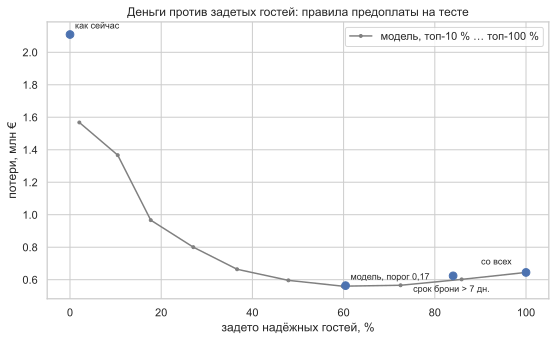

In [5]:
main_rules = overall[~overall.index.str.contains('топ')]
top_rules = overall[overall.index.str.contains('топ')]
fig, ax = plt.subplots()
ax.plot(top_rules['touched_reliable'] * 100, top_rules['total'] / 1e6, marker='.', color='grey',
        label='модель, топ-10 % … топ-100 %')
ax.scatter(main_rules['touched_reliable'] * 100, main_rules['total'] / 1e6, s=60, zorder=3)
for name, row in main_rules.iterrows():
    offset = {'со всех': (-45, 8)}.get(name, (-40, -16) if name.startswith('срок') else (5, 6))
    ax.annotate(name, (row['touched_reliable'] * 100, row['total'] / 1e6), textcoords='offset points',
                xytext=offset, fontsize=9)
ax.set_title('Деньги против задетых гостей: правила предоплаты на тесте')
ax.set_xlabel('задето надёжных гостей, %')
ax.set_ylabel('потери, млн €')
ax.legend()
save_figure(fig, '14_policies')
plt.show()

Каждая точка — правило: по горизонтали доля задетых надёжных гостей, по вертикали потери.

Серая линия — топ-10 % … топ-100 %: потери быстро падают с 1,568 млн € (топ-10 %, задето 2,0 % надёжных) до 0,664 (топ-50 %, задето 36,6 %), дальше почти не меняются: минимум 0,560 при топ-70 % (задето 59,8 %), а к топ-100 % (это и есть «со всех») снова растут до 0,645.

Порог 0,17 лежит у самого дна кривой (0,564) — он берёт предоплату с 70,4 % броней, почти как топ-70 %; топ-70 % на тесте чуть лучше, но эту долю мы увидели задним числом, а порог выбран заранее на валидации.

Правее дна предоплата уже не экономит деньги, а только задевает гостей — там и лежат «срок брони > 7 дн.» и «со всех».

**Вывод.** «Как сейчас» отель теряет 2,11 млн €, и основные правила с предоплатой («со всех», по сроку, порог модели) сокращают потери в 3–4 раза.

«Со всех» почти так же выгодно, как лучшее правило (0,645 против 0,564 млн €, разница 0,081), но задевает всех надёжных гостей.

Правило по сроку при подобранном N = 7 вырождается почти в «со всех» (88,2 % броней): при допущениях 50 % / 10 % пропущенная отмена в 5 раз дороже лишней предоплаты, и подбор N по деньгам толкает правило брать предоплату почти со всех.

Модель с порогом теряет меньше всех основных правил и задевает 60 % надёжных гостей; если это много, топ-X % — это выбор «деньги против гостей»: бизнес выбирает точку на кривой, например топ-50 % — потери 0,66 млн €, задето 37 %.

## 4. Сравнение при равной доле предоплаты

**Что делаем.** Правила из раздела 3 берут предоплату с разной доли броней, поэтому сравнивать их «в лоб» нечестно: правило, которое берёт предоплату почти со всех, ловит почти все отмены, но и задевает почти всех надёжных гостей.

Ставим модель и простое правило в равные условия: для каждой доли броней с предоплатой (5 %, 10 %, …, 100 %) выбираем брони двумя способами — по риску модели и по сроку брони (самые ранние) — и сравниваем потери и задетых гостей.

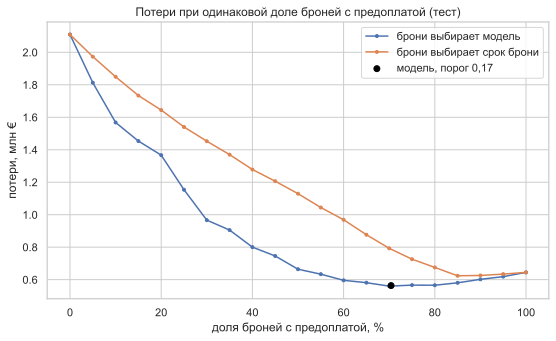

In [6]:
curves = equal_share_curves(test_s)
curves.to_csv(CURVES_PATH, index=False)
pooled = curves[curves['hotel'] == ALL_HOTELS]
fig, ax = plt.subplots()
for method, part in pooled.groupby('method'):
    ax.plot(part['share'] * 100, part['total'] / 1e6, marker='.', label=f'брони выбирает {method}')
rule = overall.loc[overall.index.str.startswith('модель, порог')].iloc[0]
ax.scatter(rule['prepay_share'] * 100, rule['total'] / 1e6, color='black', zorder=3, label=rule.name)
ax.set_title('Потери при одинаковой доле броней с предоплатой (тест)')
ax.set_xlabel('доля броней с предоплатой, %')
ax.set_ylabel('потери, млн €')
ax.legend()
save_figure(fig, '15_equal_share')
plt.show()

Две линии — потери при одной и той же доле броней с предоплатой: синяя — брони выбирает модель (самые рискованные), оранжевая — срок брони (самые ранние).

Обе начинаются в 2,109 млн € (предоплаты нет ни у кого) и сходятся в 0,645 при 100 % (предоплата со всех), а между этими краями синяя линия всё время ниже — при любой доле модель выбирает брони лучше.

Чёрная точка — правило «модель, порог 0,17» (70,4 % броней, 0,564 млн €): она лежит у дна синей линии, где дальнейшее расширение предоплаты уже не экономит.

In [7]:
equal = pooled[pooled['share'].isin([0.3, 0.5, 0.7, 0.9])].assign(total=pooled['total'] / 1e6)
equal.pivot(index='share', columns='method', values=['total', 'touched_reliable', 'caught_cancels']).round(3)

total            touched_reliable            caught_cancels           
method модель срок брони           модель срок брони         модель срок брони
share                                                                         
0.3     0.967      1.453            0.177      0.263          0.520      0.364
0.5     0.664      1.129            0.366      0.456          0.751      0.581
0.7     0.560      0.793            0.598      0.646          0.898      0.806
0.9     0.602      0.626            0.859      0.864          0.981      0.975

Таблица — те же линии в четырёх точках. Строка — доля броней с предоплатой; для каждого показателя две колонки: брони выбирает модель или срок брони; `total` — потери в млн €, `touched_reliable` — доля задетых надёжных гостей, `caught_cancels` — доля пойманных отмен.

Пример — строка 0,5 (предоплата с половины броней): если выбирает модель, отель теряет 0,664 млн €, задевает 36,6 % надёжных гостей и ловит 75,1 % отмен; если срок брони — теряет 1,129 млн €, задевает 45,6 % и ловит 58,1 %.

При 30 % разница в потерях 0,967 против 1,453, при 70 % — 0,560 против 0,793, а при 90 % почти исчезает: 0,602 против 0,626, задето 85,9 % против 86,4 %.

**Вывод.** **Главный ответ на вопрос «зачем модель, если "со всех" почти так же выгодно».**

«Со всех» выгодно только потому, что задевает всех надёжных гостей. Если отель хочет брать предоплату не со всех, модель при той же доле броней теряет заметно меньше, чем выбор по сроку: при 30 % — 0,97 против 1,45 млн €, при 50 % — 0,66 против 1,13, при 70 % — 0,56 против 0,79, и при этом задевает меньше надёжных гостей и ловит больше отмен.

Около 90–100 % способы сходятся (0,602 против 0,626 при 90 %): если отель готов брать предоплату почти со всех, модель не нужна.

## 5. Разрез по отелям

**Что делаем.** Повторяем сравнение правил отдельно для городского и курортного отеля: правила применяются внутри отеля («топ-X %» — X % броней этого отеля).

На шаге 2 (H5) доля отмен в городском отеле была заметно выше — проверяем, меняет ли это выбор правила.

In [8]:
shown = ~policies['policy'].str.contains('топ') | policies['policy'].eq('модель, топ-50 %')
by_hotel = policies[shown & (policies['hotel'] != ALL_HOTELS)]
by_hotel = by_hotel.assign(total=by_hotel['total'] / 1e6, saving=by_hotel['saving'] / 1e6)
by_hotel.pivot(index='policy', columns='hotel', values=['total', 'saving', 'touched_reliable']).round(3)

total                  saving               \
hotel              City Hotel Resort Hotel City Hotel Resort Hotel   
policy                                                               
как сейчас              1.058        1.052      0.000        0.000   
модель, порог 0,17      0.311        0.253      0.747        0.799   
модель, топ-50 %        0.377        0.260      0.680        0.792   
со всех                 0.339        0.306      0.719        0.746   
срок брони > 7 дн.      0.330        0.294      0.728        0.758   

                   touched_reliable               
hotel                    City Hotel Resort Hotel  
policy                                            
как сейчас                    0.000        0.000  
модель, порог 0,17            0.689        0.458  
модель, топ-50 %              0.381        0.342  
со всех                       1.000        1.000  
срок брони > 7 дн.            0.863        0.801

Таблица — правила внутри каждого отеля (деньги в млн €): `total` — потери, `saving` — экономия против «как сейчас» в том же отеле, `touched_reliable` — доля задетых надёжных гостей.

Пример — строка «модель, порог 0,17»: в City Hotel потери 0,311, задето 68,9 % надёжных гостей, в Resort Hotel — 0,253 и 45,8 %.

«Как сейчас» оба отеля теряют почти одинаково (1,058 и 1,052), то есть больше задетых гостей в городском отеле — не потому, что там на тесте больше отмен: модель считает его брони рискованнее (это проверяем в следующей ячейке).

В обоих отелях порог модели теряет меньше всех показанных правил (среди всех долей топ-X % на тесте нашлись чуть лучшие: в City Hotel топ-80 % — 0,301, в Resort Hotel топ-70 % — 0,251, но эти доли видны только задним числом, как и в разделе 3), а топ-50 % ведёт себя по-разному: в Resort Hotel он почти так же хорош, как порог (0,260 против 0,253), и задевает 34,2 % гостей вместо 45,8 %, а в City Hotel хуже даже «со всех» (0,377 против 0,339).

In [9]:
pd.DataFrame({'отель': test_s.hotel, 'средний риск модели': test_s.proba,
              'доля отмен на деле': test_s.canceled}).groupby('отель').mean().round(3)

,средний риск модели,доля отмен на деле
отель,,
City Hotel,0.379,0.352
Resort Hotel,0.295,0.342


Проверяем, почему в городском отеле порог задевает больше гостей. Средний риск отмены, который модель ставит броням теста, — 0,379 в City Hotel и 0,295 в Resort Hotel, а на деле отменили почти одинаково: 0,352 и 0,342.

Значит, модель считает брони городского отеля рискованнее, чем они оказались, а курортного — надёжнее: чаще отправляет городские брони под предоплату и чаще задевает там надёжных гостей.

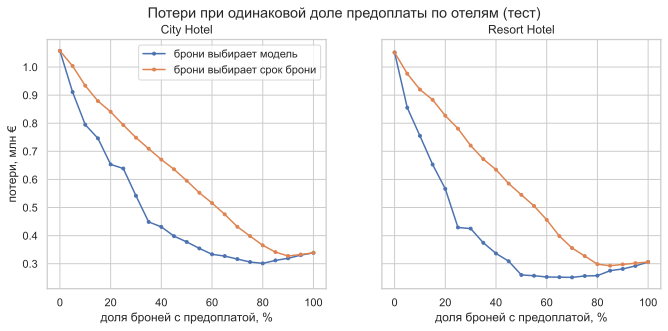

In [10]:
hotel_curves = curves[curves['hotel'] != ALL_HOTELS]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (hotel, part) in zip(axes, hotel_curves.groupby('hotel')):
    for method, line in part.groupby('method'):
        ax.plot(line['share'] * 100, line['total'] / 1e6, marker='.', label=f'брони выбирает {method}')
    ax.set_title(hotel)
    ax.set_xlabel('доля броней с предоплатой, %')
axes[0].set_ylabel('потери, млн €')
axes[0].legend()
fig.suptitle('Потери при одинаковой доле предоплаты по отелям (тест)')
save_figure(fig, '16_hotels')
plt.show()

Те же кривые «равной доли», что в разделе 4, но отдельно для каждого отеля (шкала потерь общая).

В обоих отелях синяя линия (брони выбирает модель) ниже оранжевой (срок брони) почти на всём пути и сходится с ней у 100 %.

У курортного отеля линия модели выходит на «полку» уже около 50 % броней (топ-50 % — 0,260 млн €), а у городского продолжает снижаться дольше — поэтому в городском отеле выгодно брать предоплату с большей доли броней.

**Вывод.** Вывод о выборе правила одинаков для обоих отелей: порог модели теряет меньше всех показанных правил (0,311 млн € в City Hotel, 0,253 в Resort Hotel; топ-80 % в City Hotel и топ-70 % в Resort Hotel на тесте чуть дешевле — 0,301 и 0,251, — но эти доли видны только задним числом), «со всех» и «срок брони» — дороже и задевают около 80–100 % надёжных гостей.

Различается цена для гостей: в городском отеле порог задевает 68,9 % надёжных гостей, в курортном — 45,8 %, а компромисс топ-50 % хорошо работает только в курортном.

Это связано с H5 шага 2: на истории (обучение и валидация) городской отель отменял заметно чаще, и модель переносит этот повышенный риск на тест — средний риск 0,379 против 0,295 при фактической доле отмен 0,352 и 0,342. Это связь, а не причина.

## 6. Чувствительность к допущениям

**Что делаем.** Допущения 50 % и 10 % взяты не из данных, поэтому проверяем, меняется ли вывод при других значениях: доля неперепроданного 0,3–0,7 и вероятность потерять гостя 0,05–0,2.

Для каждой пары заново подбираем N для правила по сроку (на валидации) и порог модели — по простой формуле `loss_prob / (unsold_share + loss_prob)`: при исправленных вероятностях она сразу даёт лучший порог. Затем сравниваем четыре правила на тесте и смотрим, какое лучше.

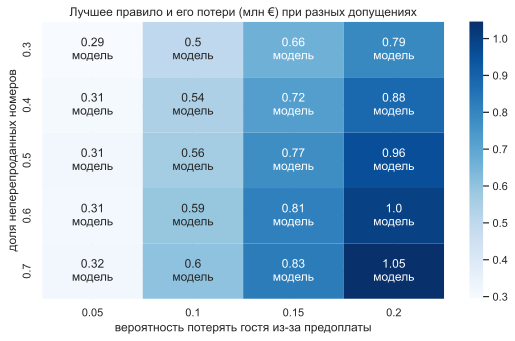

In [11]:
sensitivity = policy_sensitivity(valid_s, test_s, [0.3, 0.4, 0.5, 0.6, 0.7], [0.05, 0.1, 0.15, 0.2])
best_total = sensitivity.pivot(index='unsold_share', columns='loss_prob', values='best_total') / 1e6
best_rule = sensitivity.pivot(index='unsold_share', columns='loss_prob', values='best')
fig, ax = plt.subplots()
sns.heatmap(best_total, annot=best_total.round(2).astype(str) + '\n' + best_rule, fmt='', cmap='Blues', ax=ax)
ax.set_title('Лучшее правило и его потери (млн €) при разных допущениях')
ax.set_xlabel('вероятность потерять гостя из-за предоплаты')
ax.set_ylabel('доля неперепроданных номеров')
save_figure(fig, '17_policy_sensitivity')
plt.show()

Тепловая карта — таблица, где цвет ячейки показывает число: строка — доля неперепроданного (0,3–0,7), столбец — вероятность потерять гостя (0,05–0,2), в ячейке — потери лучшего правила (млн €) и его название.

Во всех 20 ячейках лучшее правило — модель. Её потери растут от 0,29 млн € (0,3 и 0,05) до 1,05 (0,7 и 0,2); в нашей основной точке (0,5 и 0,1) — 0,56.

В выбранных диапазонах потери растут сильнее вправо, чем вниз: цена потери гостя влияет на итог больше, чем доля неперепроданного.

In [12]:
gap = sensitivity.assign(**{'модель лучше «со всех», млн €': (sensitivity['со всех'] - sensitivity['модель']) / 1e6,
                            'модель лучше срока, млн €': (sensitivity['срок брони'] - sensitivity['модель']) / 1e6})
gap[['unsold_share', 'loss_prob', 'lead_days', 'threshold', 'модель лучше «со всех», млн €',
     'модель лучше срока, млн €']].round(3)

,unsold_share,loss_prob,lead_days,threshold,"модель лучше «со всех», млн €","модель лучше срока, млн €"
0,0.3,0.05,5,0.143,0.028,0.021
1,0.3,0.10,8,0.250,0.146,0.114
2,0.3,0.15,17,0.333,0.305,0.236
3,0.3,0.20,159,0.400,0.500,0.393
4,0.4,0.05,1,0.111,0.015,0.012
5,0.4,0.10,7,0.200,0.102,0.075
6,0.4,0.15,8,0.273,0.243,0.192
7,0.4,0.20,17,0.333,0.407,0.315
8,0.5,0.05,1,0.091,0.007,0.006
9,0.5,0.10,7,0.167,0.081,0.060


Таблица — те же 20 пар допущений: `lead_days` — N для правила по сроку, подобранный на валидации, `threshold` — порог модели, последние две колонки — насколько модель теряет меньше, чем «со всех» и чем срок брони (млн €).

Пример — строка 9 (0,5 и 0,1, наши допущения): N = 7, порог 0,167, модель лучше «со всех» на 0,081 млн € и срока — на 0,060.

При дешёвом уходе гостя (`loss_prob = 0,05`) выигрыш над «со всех» — всего 0,006–0,028 млн €, а при `loss_prob = 0,2` — 0,244–0,500.

N меняется от 1 до 159 дней, порог — от 0,067 до 0,400: N = 1 — это почти «со всех» (без предоплаты остаются только брони за день до заезда и в день заезда), а N = 159 — предоплата лишь с очень ранних броней, правило почти выключено.

**Вывод.** При всех 20 парах допущений лучшее правило — модель, так что сам выбор правила от допущений не зависит.

Но величина выигрыша зависит сильно: если гость почти не уходит из-за предоплаты (`loss_prob = 0,05`), модель лучше «со всех» лишь на сотые доли млн € (0,006–0,028), то есть почти ничего не даёт; чем дороже потеря гостя, тем больше выигрыш (до 0,500 млн € при 0,2).

N для срока (1–159 дней) и порог модели (0,067–0,400) меняются вместе с допущениями — если отель уточнит цены, их надо пересчитать.

## 7. Овербукинг

**Что делаем.** Для каждой даты заезда считаем, сколько отмен ждать, двумя способами:

- **ожидание** — сумма исправленных вероятностей отмены всех броней даты (например, 100 броней по 30 % — ждём 30 отмен);
- **осторожная оценка** — число отмен, которое наберётся почти наверняка, с вероятностью не ниже 90 %. Для этого считаем вероятность получить 0, 1, 2, … отмен на дату, когда у каждой брони свой риск (в статистике это называется пуассон-биномиальным распределением): точно, добавляя брони по одной и считая отмены независимыми.

**Бенчмарк без модели** — для сравнения: вместо риска модели каждой брони ставим долю отмен её ячейки «месяц × день недели» на обучении и делаем те же расчёты.

Проверяем на тесте: сколько номеров удалось бы перепродать и сколько раз гостю не хватило бы номера.

In [13]:
bench = benchmark_proba(benchmark_rates(train), test, fallback=train['is_canceled'].mean())
dates = date_table(test, test_proba, bench)
dates.to_csv(OVERBOOKING_PATH, index=False)
errors = dates.assign(model_error=(dates['expected'] - dates['actual']).abs(),
                      bench_error=(dates['bench_expected'] - dates['actual']).abs(),
                      model_short=dates['cautious'] > dates['actual'],
                      bench_short=dates['bench_cautious'] > dates['actual'])
errors.groupby('hotel')[['actual', 'expected', 'bench_expected', 'cautious', 'bench_cautious', 'model_error',
                         'bench_error', 'model_short', 'bench_short']].mean().round(2)

,actual,expected,bench_expected,cautious,bench_cautious,model_error,bench_error,model_short,bench_short
hotel,,,,,,,,,
City Hotel,32.14,34.67,25.19,29.52,19.85,4.49,7.41,0.27,0.00
Resort Hotel,17.80,15.32,14.30,11.70,10.26,3.34,4.49,0.02,0.04
все отели,49.94,49.99,39.50,43.60,32.68,4.43,10.72,0.11,0.00


Таблица — средние по датам заезда теста, отдельно по отелям и вместе. Колонки:

- `actual` — сколько отмен случилось;
- `expected` — ожидание модели, `bench_expected` — ожидание бенчмарка (простого правила без модели);
- `cautious` и `bench_cautious` — осторожные оценки (столько номеров можно продать сверх броней);
- `model_error` и `bench_error` — средняя ошибка ожидания в штуках;
- `model_short` и `bench_short` — доля дат, где осторожная оценка оказалась больше факта, то есть кому-то из гостей не хватило бы номера.

Пример — строка City Hotel: в среднем на дату 32,14 отмены, модель ждала 34,67 (переоценка), бенчмарк — 25,19 (недооценка); осторожная оценка модели 29,52, и в 27 % дат она оказалась больше факта.

В Resort Hotel наоборот: факт 17,80, модель ждала 15,32 (недооценка), перебор — лишь в 2 % дат.

По двум отелям вместе модель почти точна (49,99 против 49,94), а бенчмарк занижает (39,50) и ошибается в среднем на 10,72 отмены против 4,43 у модели.

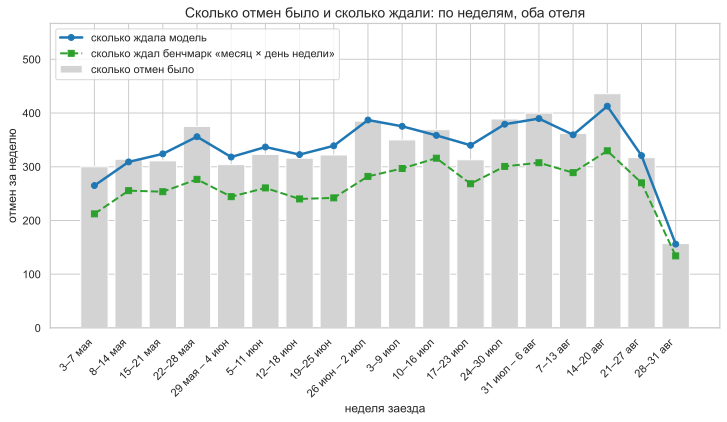

недель: 18, среднее число отмен за неделю: 336
средняя ошибка за неделю, отмен: модель 13.3, бенчмарк 70.2
в процентах от фактических отмен: модель 4.0%, бенчмарк 20.9%
недель, где бенчмарк ниже факта: 18


In [14]:
weeks = weekly_table(dates)
labels = week_labels(weeks)
x = range(len(weeks))
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.bar(x, weeks['actual'], color='lightgrey', label='сколько отмен было')
ax.plot(x, weeks['expected'], color='tab:blue', marker='o', linewidth=2.5, label='сколько ждала модель')
ax.plot(x, weeks['bench_expected'], color='tab:green', marker='s', linestyle='--', linewidth=2,
        label='сколько ждал бенчмарк «месяц × день недели»')
ax.set_xticks(list(x))
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=11)
ax.set_title('Сколько отмен было и сколько ждали: по неделям, оба отеля', fontsize=14)
ax.set_xlabel('неделя заезда', fontsize=12)
ax.set_ylabel('отмен за неделю', fontsize=12)
ax.tick_params(axis='y', labelsize=11)
ax.set_ylim(top=weeks['actual'].max() * 1.3)
ax.legend(loc='upper left', fontsize=11, ncol=1)
save_figure(fig, '18_overbooking')
plt.show()
print(f'недель: {len(weeks)}, среднее число отмен за неделю: {weeks["actual"].mean():.0f}')
print('средняя ошибка за неделю, отмен: модель '
      f'{(weeks["expected"] - weeks["actual"]).abs().mean():.1f}, '
      f'бенчмарк {(weeks["bench_expected"] - weeks["actual"]).abs().mean():.1f}')
print('в процентах от фактических отмен: модель '
      f'{(weeks["expected"] - weeks["actual"]).abs().sum() / weeks["actual"].sum():.1%}, '
      f'бенчмарк {(weeks["bench_expected"] - weeks["actual"]).abs().sum() / weeks["actual"].sum():.1%}')
print(f'недель, где бенчмарк ниже факта: {(weeks["bench_expected"] < weeks["actual"]).sum()}')

Серые столбики — сколько отмен было за неделю заезда (оба отеля вместе), синяя линия — сколько их ждала модель, зелёная пунктирная — сколько ждал бенчмарк «месяц × день недели». Первая и последняя недели неполные (3–7 мая и 28–31 августа), поэтому они короче остальных.

За неделю в среднем отменялось 336 броней. Модель в среднем ошибалась на 13,3 отмены за неделю, то есть на 4,0 % от фактических отмен, а бенчмарк — на 70,2 отмены, на 20,9 %. Синяя линия идёт рядом с вершинами столбиков, а зелёная во все 18 недель лежит ниже факта: бенчмарк обучен на периоде, где отмен было меньше (24,7 % на обучении против 34,8 % на тесте), и поэтому систематически недооценивает их.

Для бизнеса это значит, что по неделям на модель можно опираться: она показывает и подъёмы, и спады отмен. В интерактивном отчёте такой же недельный график есть отдельно по каждому отелю.

In [15]:
outcomes = outcome_table(dates)
outcomes.assign(gain=outcomes['gain'] / 1e6, walk_cost=outcomes['walk_cost'] / 1e6,
                net=outcomes['net'] / 1e6).round(3)

,plan,walk_cost_share,resold,short_dates,walked,gain,walk_cost,net
0,модель,0.5,4898.0,36.0,90.0,3.199,0.025,3.174
1,модель,1.0,4898.0,36.0,90.0,3.199,0.049,3.150
2,модель,2.0,4898.0,36.0,90.0,3.199,0.099,3.100
3,бенчмарк,0.5,3635.0,5.0,8.0,2.393,0.002,2.391
4,бенчмарк,1.0,3635.0,5.0,8.0,2.393,0.004,2.389
5,бенчмарк,2.0,3635.0,5.0,8.0,2.393,0.008,2.386


Итог овербукинга по отелям (каждый отель решает за себя): каждая строка — план (модель или бенчмарк) при цене «гостя без номера» 0,5, 1 или 2 стоимости брони. Колонки:

- `resold` — сколько номеров перепродано (не больше числа отмен);
- `short_dates` — в скольких парах «отель × дата» продали лишнее;
- `walked` — сколько гостей осталось бы без номера;
- `gain` — выручка от перепроданных номеров;
- `walk_cost` — цена «гостей без номера»;
- `net` — итог (млн €).

Пример — строка модели при цене 1: перепродано 4 898 номеров (3,199 млн €), в 36 парах «отель × дата» 90 гостям не хватило бы номера (0,049 млн €), итог 3,150 млн €; у бенчмарка — 3 635 номеров, 5 пар, 8 гостей, итог 2,389.

Даже при цене 2 итог модели почти не меняется (3,100), потому что «гостей без номера» мало по сравнению с перепроданными номерами.

Это верхняя оценка: считаем, что на каждый перепроданный номер найдётся покупатель и вся его стоимость — добавка; в разделах 3–6 мы допускали, что половину стоимости отменённых броней отель и так возвращает перепродажей, и тогда реальная добавка от овербукинга может быть примерно вдвое меньше.

**Вывод.** В среднем по датам модель почти точна (ожидала 50,0 отмены при факте 49,9), но по отелям — нет: в городском отеле переоценивает (34,67 против 32,14), в курортном недооценивает (15,32 против 17,80).

Поэтому осторожная оценка «90 %» на деле даёт перебор в 27 % дат городского отеля вместо обещанных не более 10 %: отмены не независимы (группа отменяет сразу много броней), а поправка вероятностей общая для двух отелей.

Бенчмарк перебирает редко, но только потому, что систематически занижает отмены, и перепродаёт на 1 263 номера меньше.

Сравнение не вполне равное: доли бенчмарка взяты только с обучения, а поправочная таблица модели подобрана на более поздней валидации, где отмен уже больше, — поэтому заметная часть разрыва (ошибка 4,43 против 10,72, итог 3,150 против 2,389 млн €) объясняется тем, что бенчмарк привязан к старой, более низкой доле отмен, а не только лучшим ранжированием броней.

В деньгах модель выгоднее (3,150 против 2,389 млн € при цене «гостя без номера» 1), но это при допущении, что спрос на перепроданные номера есть.

Главное ограничение: вместимости отелей в данных нет — перепродажа считается сверх фактически забронированного, а не сверх свободных номеров; овербукировать стоит осторожно, по каждому отелю отдельно и с запасом против групповых отмен.

## 8. Интерактивный отчёт

**Что делаем.** Собираем `reports/report.html` — один файл, который открывается в любом браузере без Python и без интернета (библиотека графиков встроена в файл).

Отчёт только рисует таблицы `reports/*.csv`, которые сохранили разделы 3, 4 и 7; добавляем таблицу риска по сегментам и месяцам для четвёртого графика.

Если понадобится Streamlit или BI (DataLens, Tableau), переделывается только витрина: Streamlit переиспользует функции и графики Plotly, BI — CSV.

In [16]:
risk = risk_table(test, test_proba)
risk.to_csv(RISK_PATH, index=False)
report = build_report()
pd.Series({'файл': report.name, 'размер, МБ': round(report.stat().st_size / 1e6, 1),
           'разделов': len(SECTIONS)})

файл          report.html
размер, МБ            4.9
разделов                5
dtype: object

Функция собрала `reports/report.html` размером 5,0 МБ с 5 разделами: 4 интерактивных графика (кривая «доля предоплаты — потери» для модели и срока брони; топ-X % с выпадающим списком отеля и ползунком доли; календарь овербукинга; риск по сегментам и месяцам) и раздел допущений и ограничений.

Размер — из-за встроенной библиотеки графиков Plotly: файл открывается в любом браузере без Python и без интернета, его можно просто переслать.

Отчёт статичный: переключатели заготовлены заранее для каждого графика, а произвольные комбинации фильтров («отель × сегмент × месяц») он не пересчитывает. Для этого есть дашборд `reports/dashboard.html` (раздел 12): он пересчитывает цифры по любым фильтрам прямо в браузере.

In [17]:
risk[risk['hotel'] == ALL_HOTELS].pivot(index='market_segment', columns='arrival_month',
                                        values='mean_proba').round(2)

arrival_month,5,6,7,8
market_segment,,,,
Aviation,0.19,0.21,0.16,0.11
Complementary,0.12,0.13,0.15,0.10
Corporate,0.13,0.19,0.19,0.15
Direct,0.20,0.21,0.21,0.19
Groups,0.32,0.47,0.37,0.19
Offline TA/TO,0.17,0.18,0.19,0.18
Online TA,0.39,0.43,0.42,0.44


Таблица — статичный двойник графика 4 отчёта: средний риск отмены по модели для каждого сегмента продаж (строка) и месяца заезда (столбец), оба отеля вместе.

Пример — строка Online TA (онлайн-агентства): риск 0,39 в мае, 0,43 в июне, 0,42 в июле и 0,44 в августе — стабильно высокий.

У Groups (групповые брони) риск сильно меняется по месяцам: 0,47 в июне и 0,19 в августе; у остальных сегментов — от 0,10 до 0,21.

Это связь, а не причина: сегмент не вызывает отмену, но помогает понять, где модель видит риск.

In [18]:
scored_frame(test, test_proba).to_csv(SCORED_TEST_PATH, index=False)
pd.Series({'броней теста': len(test)}, name='сохранено')

броней теста    17351
Name: сохранено, dtype: int64

Сохраняем для дашборда таблицу `reports/scored_test.csv` — 17 351 бронь теста. У каждой брони — отель, сегмент, месяц заезда, срок брони, стоимость при отмене (у броней «без возврата» — 0), факт отмены и исправленная вероятность отмены.

Дашборду не нужны ни модель, ни исходные данные: он показывает тест и пересчитывает правила по этой таблице прямо в браузере.

**Вывод.** Отчёт для бизнеса — один файл `reports/report.html`, который открывается без Python и интернета; он только рисует CSV-таблицы, сохранённые в разделах 3, 4 и 7, и таблицу риска из этого раздела, поэтому его можно пересобрать или переделать витрину (Streamlit, BI) без пересчёта модели.

Онлайн-агентства рискованнее остальных сегментов во все четыре месяца (0,39–0,44), групповые брони — в мае–июле (0,32–0,47), а в августе их риск (0,19) не выше, чем у прямых броней. Это связь, а не причина.

## 9. Схема решения о предоплате

**Что делаем.** Сводим правило решения в одну схему: от брони и оценки риска до развилки «брать предоплату или нет» и итоговых потерь на тесте.

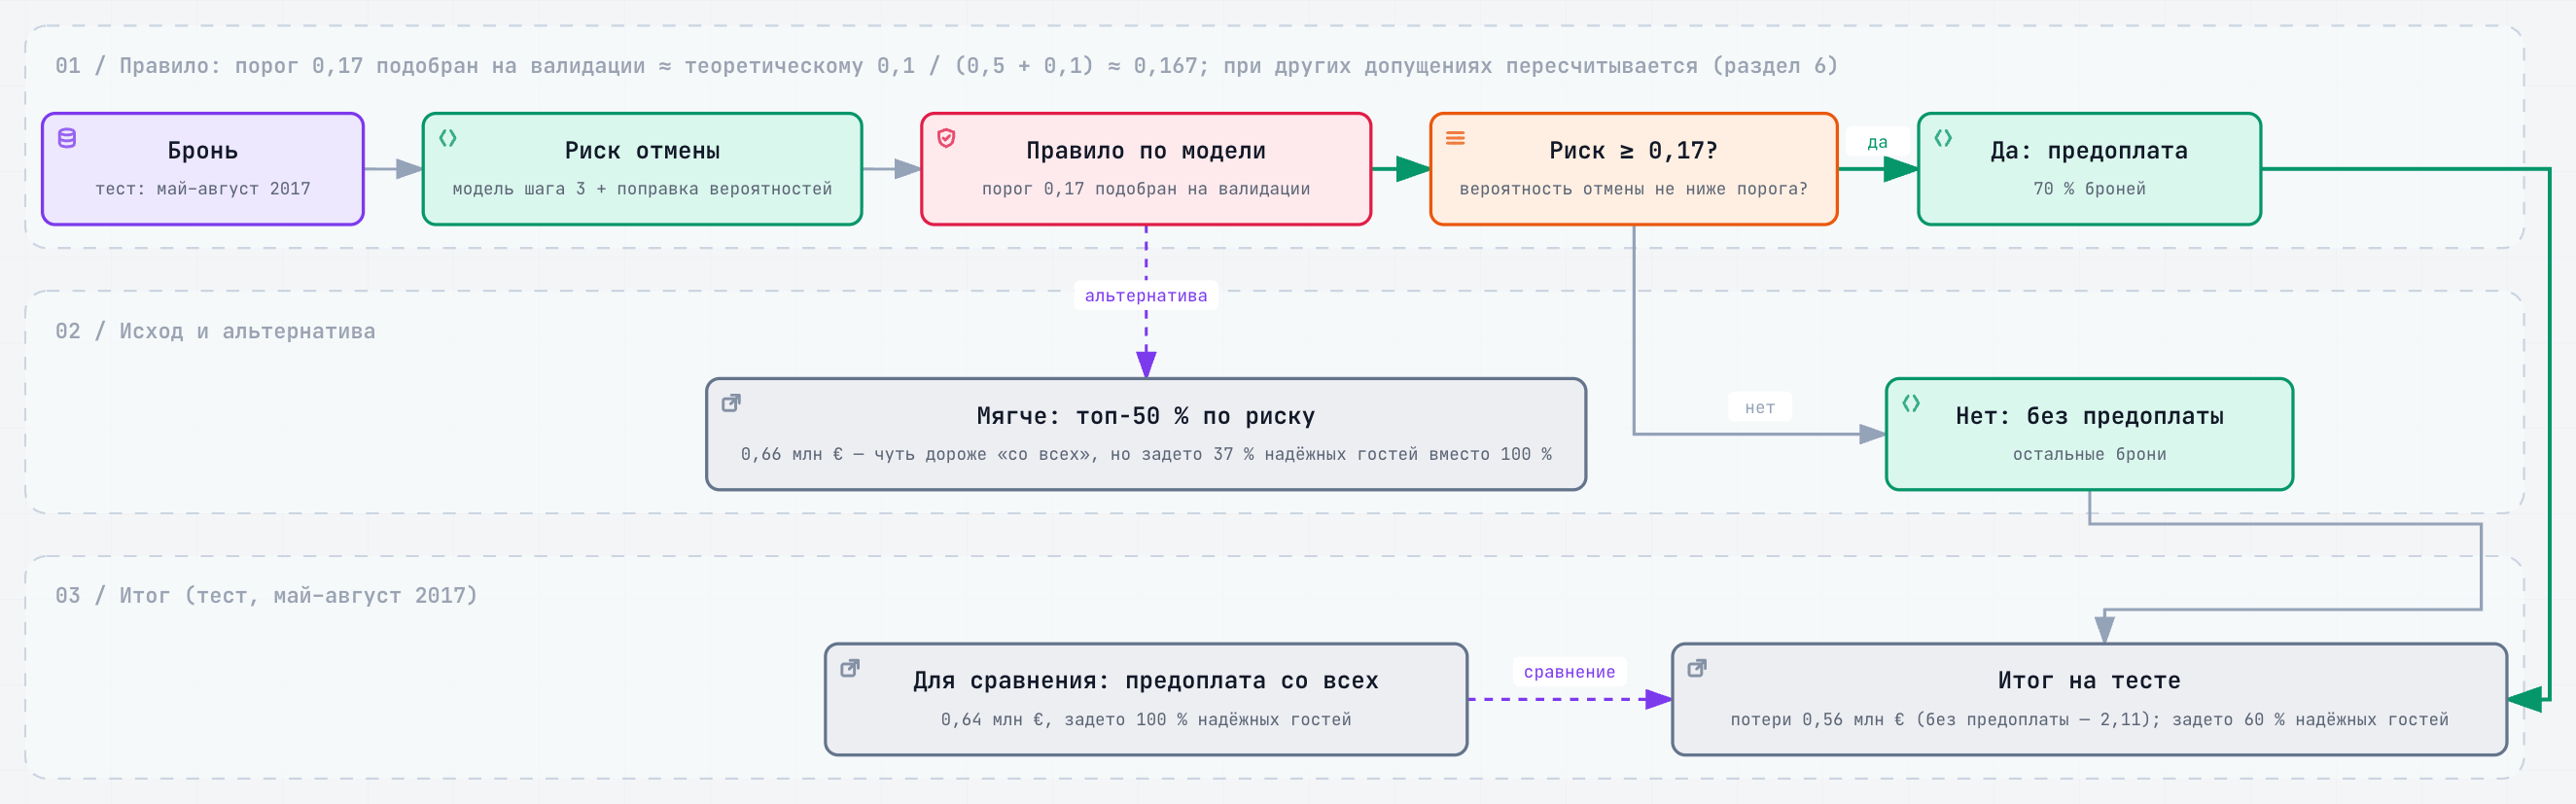

In [19]:
Image(filename=str(FIGURES_DIR / '19_prepayment_decision.png'))

Схема читается слева направо: модель оценивает риск отмены брони, правило сравнивает его с порогом 0,17 (он подобран на валидации в разделе 2 и почти совпадает с теоретическим 0,1 / (0,5 + 0,1) ≈ 0,167 из допущений раздела 1), дальше развилка «да / нет».

Цифры взяты из разделов 3 и 4: предоплата у 70 % броней, потери на тесте 0,56 млн € против 2,11 без предоплаты, задето 60 % надёжных гостей.

Серый блок «со всех» — честная базовая линия: потери 0,64 млн €, задето 100 %.

Мягкая альтернатива, топ-50 % по риску, стоит 0,66 млн € — чуть дороже «со всех», но задевает 37 % гостей вместо 100 %.

**Вывод.** Основной выигрыш от предоплаты — против «как сейчас» (0,56 против 2,11 млн €), но его даёт сама предоплата, а не модель: «со всех» тоже теряет всего 0,64.

Заслуга модели скромнее: потери чуть ниже (на ≈0,08 млн €), а надёжных гостей задето 60 % вместо 100 %. Если и 60 % много, бизнес может выбрать мягче — топ-50 % по риску, размен денег на гостей.

Порог 0,17 подобран на валидации; он почти совпадает с теоретическим 0,1 / (0,5 + 0,1) ≈ 0,167, который при других допущениях пересчитывается (раздел 6).

## 10. Выводы шага

**Инсайты и действия для бизнеса**

1. **Предоплата нужна в любом случае.** Без неё отель теряет 2,11 млн € за май–август 2017 года, с предоплатой —
   0,56–0,66 млн €. → Ввести предоплату для части броней; это даёт основную долю экономии.
2. **Брать предоплату по порогу модели или по топ-X %.** Порог 0,17 даёт минимальные потери среди основных правил
   (0,56 млн €; топ-70 % на тесте чуть лучше — 0,560 против 0,564, но эта доля видна только задним
   числом, а порог выбран заранее на валидации), однако задевает 60 % надёжных гостей. → Если это много, выбрать точку на кривой топ-X %: топ-50 % — потери
   0,66 млн €, задето 37 %. Это решение «деньги против гостей», и принимает его бизнес.
3. **Не «со всех» и не по сроку брони.** «Со всех» почти так же выгоден (0,64 млн €), но только потому, что
   задевает всех надёжных гостей; правило по сроку при подобранном N почти совпадает с ним (88 % броней). →
   При одинаковой доле предоплаты выбирать брони моделью: при 50 % потери 0,66 против 1,13 млн € у срока брони.
4. **Когда модель не нужна.** Если отель готов брать предоплату почти со всех (90–100 % броней) или гости почти
   не уходят из-за предоплаты (`loss_prob = 0,05`), выигрыш модели — сотые доли млн €. → В этих случаях хватит
   правила «со всех»; модель нужна, когда предоплату хотят брать выборочно.
5. **Отели разные.** В городском отеле порог задевает 69 % надёжных гостей, в курортном — 46 %; топ-50 % хорошо
   работает только в курортном. → Настраивать долю предоплаты отдельно для каждого отеля.
6. **Овербукинг — осторожно и по отелям.** По двум отелям вместе модель почти точна, но городской переоценивает:
   осторожная оценка «90 %» дала перебор в 27 % дат. → Овербукировать по каждому отелю отдельно и с запасом
   против групповых отмен (одна группа отменяет много броней сразу).
7. **Пересчитать при новых ценах.** Лучшее правило — модель при всех 20 парах допущений, но N для срока
   (1–159 дней) и порог (0,067–0,400) зависят от допущений. → Когда отель уточнит долю неперепроданного и
   реакцию гостей на предоплату, пересчитать порог и долю предоплаты.

**Ограничения**

- Вместимости отелей в данных нет: овербукинг считается сверх фактически забронированного, спрос на перепроданные
  номера предполагается.
- Независимость отмен — допущение; групповые отмены его нарушают, поэтому осторожная оценка перебирает чаще
  обещанного.
- Допущения о деньгах (50 % неперепроданного, 10 % ухода гостя, цена «гостя без номера») не из данных; их
  влияние проверено в разделах 6 и 7.
- Тест — брони с заездом в мае–августе 2017 года, два отеля в Португалии; на другие отели и периоды выводы
  переносятся с осторожностью.
- Итоги предоплаты (0,56 млн €) и овербукинга (3,15 млн €) не складываются: оба решения опираются на одни и те
  же отмены.
- Все связи (сегмент, срок брони, отель) — связь, а не причина.

## 11. Как собрана модель: вся цепочка на одной схеме

**Что делаем.** Собираем на одной схеме весь путь модели, по которой выбран порог 0,17: от исходной таблицы через очистку, признаки и выбор модели до порога и итога на тесте. Все цифры взяты из шагов 1, 3 и 4.

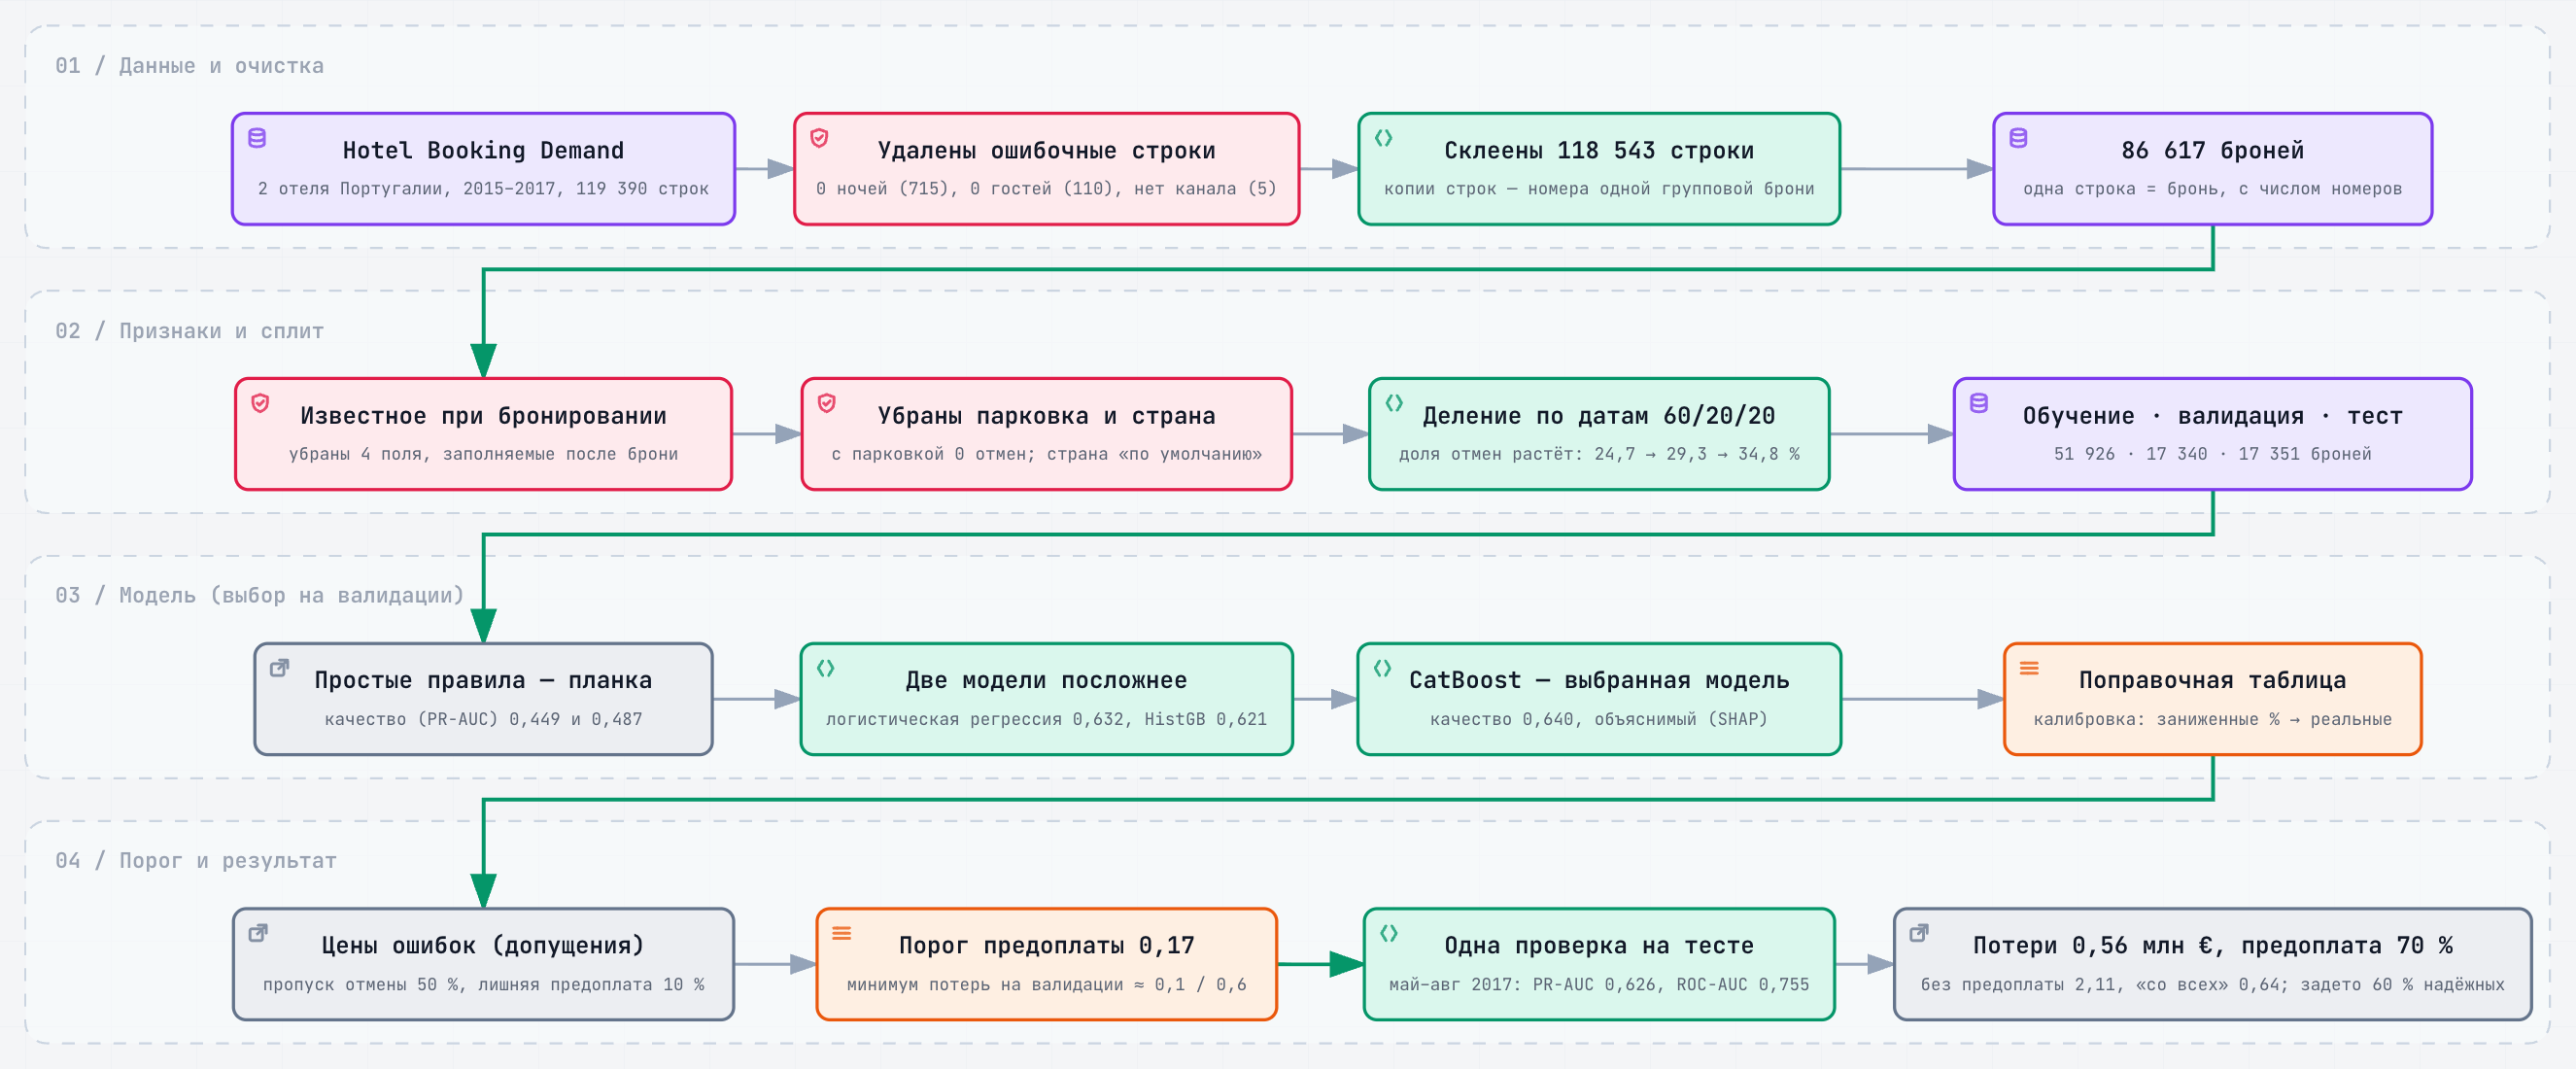

In [20]:
Image(filename=str(FIGURES_DIR / '20_model_full_pipeline.png'))

Схема читается сверху вниз, четыре блока по порядку, внутри блока — слева направо.

**01 — данные и очистка.** Исходные данные — открытый набор Hotel Booking Demand: брони двух отелей Португалии за 2015–2017 годы, 119 390 строк. Удаляем ошибки ввода (отрицательная и огромная цена, нереальные составы гостей) и записи, которые не описывают проживание: брони на 0 ночей (715), без гостей (110) и с неясным каналом продаж Undefined (5) — остаётся 118 543 строки. ID брони в данных удалён, поэтому одинаковые строки — скорее номера одной групповой брони; склеиваем их в одну бронь с числом номеров `n_rooms` и получаем 86 617 броней-решений.

**02 — признаки и сплит.** Модель видит только то, что известно в момент бронирования. Исключены четыре утечки — колонки, которые заполняются уже после брони: итоговый статус и его дата, выданный при заезде номер и число изменений брони. Исключены и две подозрительные колонки: у броней с парковкой нет ни одной отмены, а у отменённых броней чаще стоит страна «по умолчанию» (Португалия). Затем делим брони по дате заезда в пропорции 60/20/20: обучение — 51 926 (07.2015–11.2016), валидация — 17 340 (до 02.05.2017), тест — 17 351 (05–08.2017). Доля отмен со временем растёт: 24,7 → 29,3 → 34,8 %.

**03 — модель.** Все модели сравниваем на валидации по PR-AUC (насколько хорошо модель находит отмены). Простые правила без машинного обучения дают 0,449 и 0,487 — это планка. Логистическая регрессия — 0,632, HistGradientBoosting — 0,621, настроенный CatBoost — 0,640. Выбран CatBoost: он работает с категориями без ручного кодирования и хорошо объясняется (SHAP), хотя логистическая регрессия почти вровень. Модель занижала вероятности отмены, поэтому на валидации подобрана поправочная таблица (калибровка), которая приводит прогнозы к реальной доле отмен.

**04 — порог и результат.** Деньги считаем по двум допущениям: пропущенная отмена стоит 50 % стоимости брони, лишняя предоплата — 10 %. Порог, при котором потери на валидации минимальны, — 0,17; он почти совпадает с теоретическим 0,1 / 0,6. Тест открыт один раз, в самом конце: PR-AUC 0,626, ROC-AUC 0,755. При пороге 0,17 бизнес теряет 0,56 млн € против 2,11 без предоплаты и 0,64 при предоплате со всех; предоплату просим у 70 % броней, задето 60 % надёжных гостей.

**Вывод.** Порог 0,17 опирается на честно собранную модель: чистые данные, только признаки, известные при брони, выбор модели, калибровка и порог — на валидации, а тест открыт один раз. Итог — потери 0,56 млн € вместо 2,11 без предоплаты, но большую часть экономии даёт сама предоплата («со всех» — 0,64), а модель добавляет меньшую часть и задевает 60 % надёжных гостей вместо 100 %.

## 12. Дашборд для бизнеса

**Что делаем.** Собираем `reports/dashboard.html` — одну страницу, на которой бизнес сам выбирает отель, сегмент, месяц и допущения о деньгах, двигает черту «с какой доли брать предоплату» и сразу видит потери, пойманные отмены и задетых гостей.

Страница открывается двойным щелчком, без Python и без интернета: брони теста, оформление, шрифты и расчёты встроены в файл. Расчёты в браузере повторяют функции `src/dashboard.py`, а тест сверяет их цифры.

У страницы два вида. «Дашборд» — показатели и графики на одном экране, он открывается по умолчанию; «Презентация» — рассказ с пояснениями и схемами. Переключатель вверху, `dashboard.html#presentation` сразу открывает презентацию. Все графики — Plotly: вид графика задаёт Python (`src/dashboard_figures.py`), а браузер только подставляет пересчитанные данные.

In [21]:
dashboard = build_dashboard()
pd.Series({'файл': dashboard.name, 'размер, МБ': round(dashboard.stat().st_size / 1e6, 1),
           'броней теста внутри': len(pd.read_csv(SCORED_TEST_PATH))})

файл                   dashboard.html
размер, МБ                        6.6
броней теста внутри             17351
dtype: object

Функция собрала `reports/dashboard.html` размером 6,6 МБ; внутри все 17 351 бронь теста (май–август 2017). Большую часть веса занимает встроенная библиотека графиков Plotly, остальное — шрифты и данные броней: поэтому страница выглядит одинаково на любом компьютере и работает без интернета.

Схемы 19 и 20 дашборд показывает из соседних файлов `reports/figures/`, поэтому папку `reports` пересылают целиком. Интерфейс схем теперь на русском, а у каждого шага в паспорте есть пояснение простыми словами.

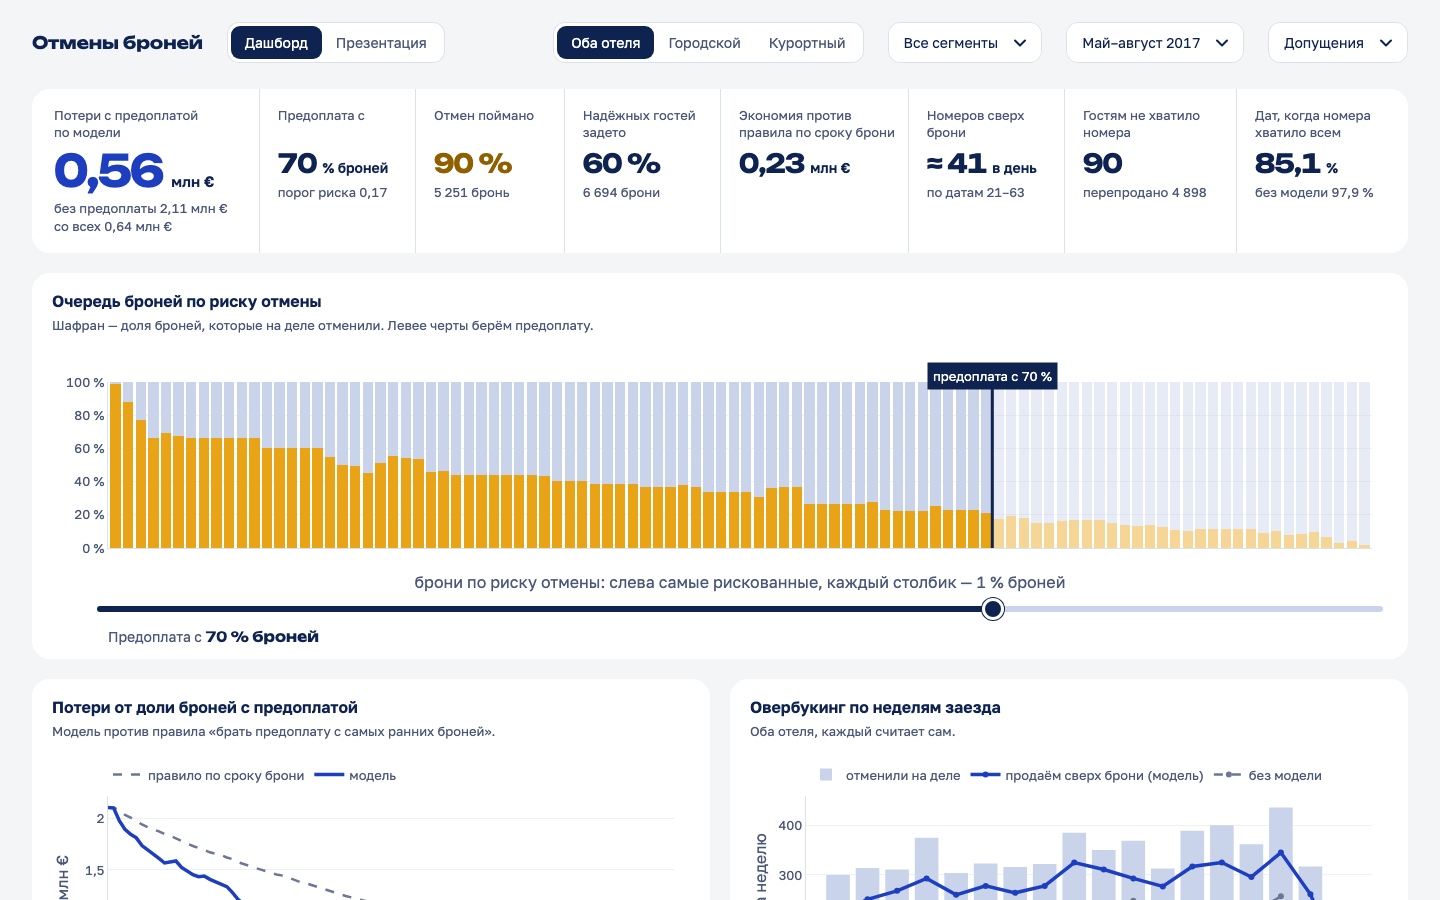

In [22]:
Image(filename=str(FIGURES_DIR / '22_dashboard_kpi.png'))

Так выглядит вид «Дашборд» при настройках по умолчанию. В полосе — восемь показателей: потери с предоплатой по модели 0,56 млн €, предоплата с 70 % броней (порог риска 0,17), поймано 90 % отмен, задето 60 % надёжных гостей, экономия против правила по сроку брони 0,23 млн €, овербукинг около 41 номера в день, 90 гостей, которым не хватило номера, и 85,1 % дат, когда номеров хватило всем (без модели — 97,9 %).

Почти вся экономия приходится на онлайн-агентства: у них потери падают с 1,77 до 0,35 млн €, то есть экономия против работы без предоплаты 1,41 млн € из 1,55 млн € всего (около 91 %). Это и самый большой сегмент — 11 658 из 17 351 брони, и в нём отменяют чаще всего (41,5 %). Это связь, а не причина: предоплата работает там, где много рискованных броней, а не потому, что сами агентства «виноваты» в отменах.

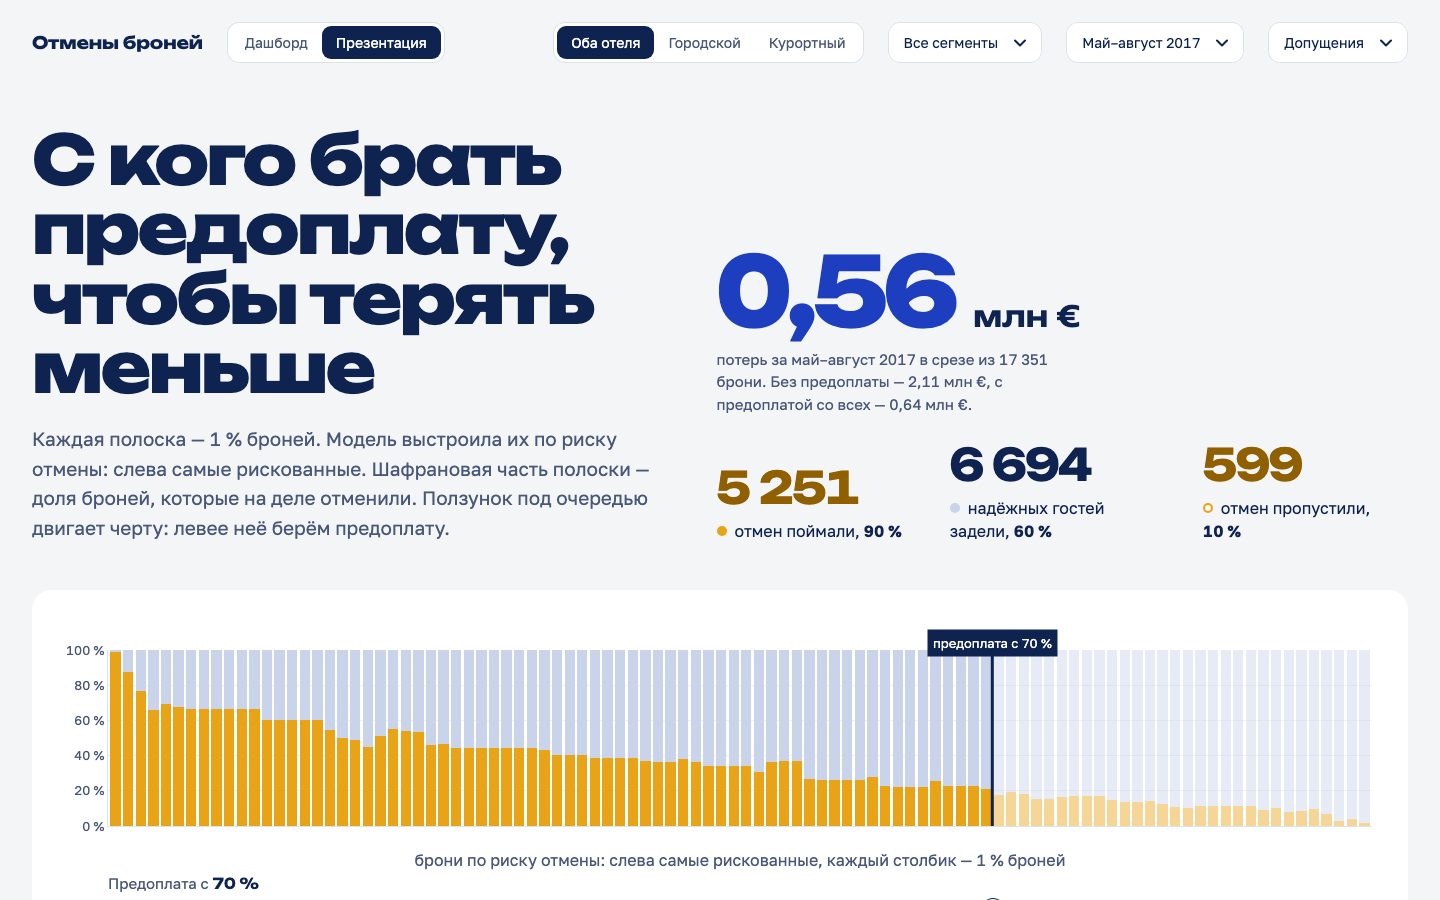

In [23]:
Image(filename=str(FIGURES_DIR / '21_dashboard.png'))

Так выглядит верх вида «Презентация» при настройках по умолчанию: оба отеля, все сегменты, май–август, допущения 50 % и 10 %. Сто полосок — это все брони теста по 1 % в каждой, слева самые рискованные; шафрановая часть полоски — доля броней, которые на деле отменили (брони с одинаковым риском показаны общей долей своей группы: модель их не различает).

Черта стоит на пороге 0,17 — это 70 % броней. Итог тот же, что в разделах 3 и 4: потери 0,56 млн € вместо 2,11 без предоплаты и 0,64 при предоплате со всех; поймано 5 251 отмена (90 %), задето 6 694 надёжных гостя (60 %), пропущено 599 отмен (10 %).

Ниже на странице — сравнение с правилом по сроку брони, овербукинг по неделям, доля отмен по сегментам и месяцам, обе схемы и три рекомендации для бизнеса.

**Вывод.** Дашборд отвечает на вопрос «а что, если…» без аналитика: можно выбрать отель или сегмент, поменять допущения и посмотреть, как меняются потери и сколько гостей задевает предоплата.

Цифры при настройках по умолчанию совпадают с ноутбуком (0,56 млн € при пороге 0,17), а честная оговорка осталась на месте: по датам заезда при осторожной оценке номера хватило всем гостям в 85,1 % дат (два отеля, каждый считается со своими датами и своим решением), в курортном — в 97,5 %, а в городском — только в 72,7 %, поэтому в городском отеле стоит продавать сверх брони меньше. Это связь, а не причина.